In [15]:
import tensorflow as tf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D
from tensorflow.keras.layers import Flatten, Dense

In [16]:
df = pd.read_csv('cifar-10.csv')

print(df.head())
print("Dataset shape:", df.shape)

   pixel_0  pixel_1  pixel_2  pixel_3  pixel_4  pixel_5  pixel_6  pixel_7  \
0       59       43       50       68       98      119      139      145   
1      154      126      105      102      125      155      172      180   
2      255      253      253      253      253      253      253      253   
3       28       37       38       42       44       40       40       24   
4      170      168      177      183      181      177      181      184   

   pixel_8  pixel_9  ...  pixel_3063  pixel_3064  pixel_3065  pixel_3066  \
0      149      149  ...          58          65          59          46   
1      142      111  ...          42          67         101         122   
2      253      253  ...          83          80          69          66   
3       32       43  ...          39          59          42          44   
4      189      189  ...          88          85          82          83   

   pixel_3067  pixel_3068  pixel_3069  pixel_3070  pixel_3071  label  
0        

In [17]:
X = df.drop('label', axis=1).values
y = df['label'].values

print("Features shape:", X.shape)
print("Labels shape:", y.shape)

Features shape: (50000, 3072)
Labels shape: (50000,)


In [18]:


# Separate features and labels
X = df.drop('label', axis=1).values
y = df['label'].values

# Normalize pixel values
X = X.astype('float32') / 255.0

# Correct RGB channel arrangement
X = X.reshape(-1, 3, 32, 32)
X = X.transpose(0, 2, 3, 1)

print("Image shape:", X.shape)

Image shape: (50000, 32, 32, 3)


In [19]:
x_train, x_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (40000, 32, 32, 3)
Testing data: (10000, 32, 32, 3)


In [20]:
class_names = [
    'Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
    'Dog', 'Frog', 'Horse', 'Ship', 'Truck'
]

In [21]:
model = tf.keras.Sequential([

    tf.keras.layers.Input(shape=(32,32,3)),

    # First Convolutional Layer
    tf.keras.layers.Conv2D(
        32, (3, 3), activation='relu'
    ),

    # First Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Second Convolutional Layer
    tf.keras.layers.Conv2D(
        64, (3, 3), activation='relu'
    ),

    # Second Max Pooling Layer
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Flatten Layer
    tf.keras.layers.Flatten(),

    # Fully Connected Layer
    tf.keras.layers.Dense(128, activation='relu'),

    # Output Layer
    tf.keras.layers.Dense(24, activation='softmax')
])

In [22]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [23]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.3986 - loss: 1.6712 - val_accuracy: 0.4913 - val_loss: 1.4441
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.5274 - loss: 1.3288 - val_accuracy: 0.5531 - val_loss: 1.2566
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.5852 - loss: 1.1701 - val_accuracy: 0.6097 - val_loss: 1.1173
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6275 - loss: 1.0689 - val_accuracy: 0.6180 - val_loss: 1.0881
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6560 - loss: 0.9851 - val_accuracy: 0.6484 - val_loss: 1.0162
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.6764 - loss: 0.9322 - val_accuracy: 0.6475 - val_loss: 1.0252
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.6974 - loss: 0.8729 - val_accuracy: 0.6646 - val_loss: 0.9878
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.7116 - loss: 0.8239 - val_accu

In [24]:
test_loss, test_accuracy = model.evaluate(
    x_test, y_test
)

print("Test Loss:", test_loss)

print("Classification Accuracy:",
      test_accuracy * 100, "%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6745 - loss: 0.9791
Test Loss: 0.9791276454925537
Classification Accuracy: 67.44999885559082 %


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step


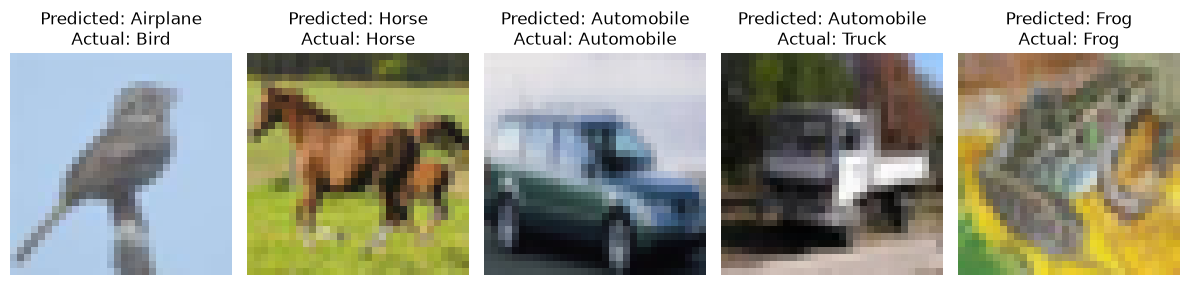

In [25]:
predictions = model.predict(x_test[:5])

predicted_labels = np.argmax(predictions, axis=1)

plt.figure(figsize=(12, 5))

for i in range(5):
    plt.subplot(1, 5, i + 1)

    plt.imshow(x_test[i])

    plt.title(
        "Predicted: " + class_names[predicted_labels[i]] +
        "\nActual: " + class_names[y_test[i]]
    )

    plt.axis('off')

plt.tight_layout()
plt.show()

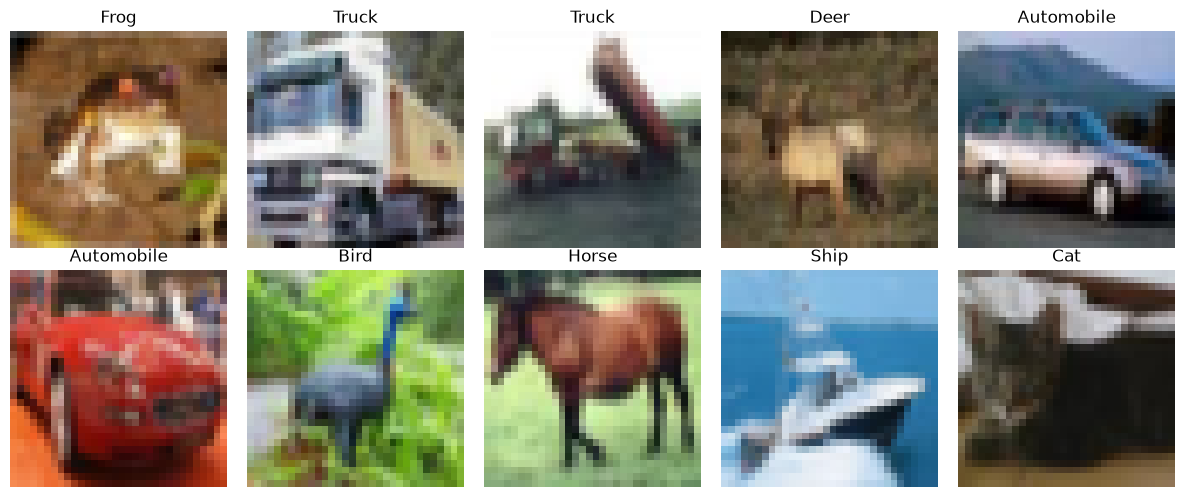

In [26]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X[i], interpolation='nearest')

    plt.title(class_names[y[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# Develop a CNN model to classify images into ten object categories.
# Perform image preprocessing, model training and testing, and display the
# classification accuracy.
# Use Dataset - CIFAR-10